<a href="https://colab.research.google.com/github/TanexKurt/Laboratories/blob/main/Gabinete_Lab4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

# Read the file directly from a public URL instead of uploading it
url = 'https://raw.githubusercontent.com/susanli2016/Machine-Learning-with-Python/master/fruit_data_with_colors.txt'
fruits = pd.read_table(url)

fruits

,fruit_label,fruit_name,fruit_subtype,mass,width,height,color_score
0,1,apple,granny_smith,192,8.4,7.3,0.55
1,1,apple,granny_smith,180,8.0,6.8,0.59
2,1,apple,granny_smith,176,7.4,7.2,0.60
3,2,mandarin,mandarin,86,6.2,4.7,0.80
4,2,mandarin,mandarin,84,6.0,4.6,0.79
5,2,mandarin,mandarin,80,5.8,4.3,0.77
6,2,mandarin,mandarin,80,5.9,4.3,0.81
7,2,mandarin,mandarin,76,5.8,4.0,0.81
8,1,apple,braeburn,178,7.1,7.8,0.92
9,1,apple,braeburn,172,7.4,7.0,0.89


In [ ]:
fruits.columns

Index(['fruit_label', 'fruit_name', 'fruit_subtype', 'mass', 'width', 'height',
       'color_score'],
      dtype='object')

In [ ]:
fname = fruits['fruit_name'].unique()
fname

array(['apple', 'mandarin', 'orange', 'lemon'], dtype=object)

In [ ]:
fsize = fruits.groupby(fruits['fruit_name'], sort = False).size()
fsize

,0
fruit_name,
apple,19
mandarin,5
orange,19
lemon,16


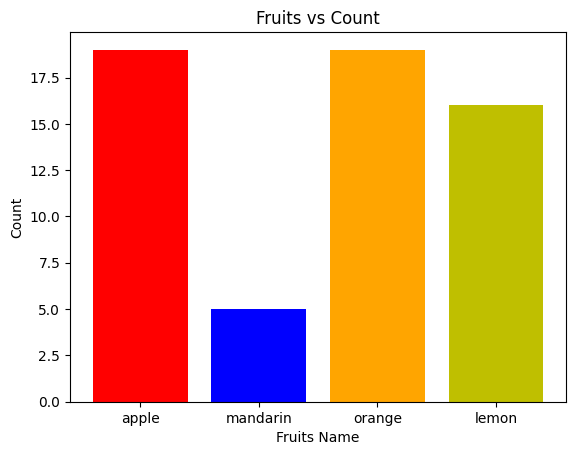

In [ ]:
import matplotlib.pyplot as plt
plt.bar(fname, fsize, color = ['r', 'blue', 'orange', 'y'])
plt.title('Fruits vs Count')
plt.xlabel('Fruits Name')
plt.ylabel('Count')
plt.show()

In [ ]:
x = fruits.iloc[:, [3,4,5,6]].values
y = fruits.iloc[:, 1].values
print(x, y)

[[192.     8.4    7.3    0.55]
 [180.     8.     6.8    0.59]
 [176.     7.4    7.2    0.6 ]
 [ 86.     6.2    4.7    0.8 ]
 [ 84.     6.     4.6    0.79]
 [ 80.     5.8    4.3    0.77]
 [ 80.     5.9    4.3    0.81]
 [ 76.     5.8    4.     0.81]
 [178.     7.1    7.8    0.92]
 [172.     7.4    7.     0.89]
 [166.     6.9    7.3    0.93]
 [172.     7.1    7.6    0.92]
 [154.     7.     7.1    0.88]
 [164.     7.3    7.7    0.7 ]
 [152.     7.6    7.3    0.69]
 [156.     7.7    7.1    0.69]
 [156.     7.6    7.5    0.67]
 [168.     7.5    7.6    0.73]
 [162.     7.5    7.1    0.83]
 [162.     7.4    7.2    0.85]
 [160.     7.5    7.5    0.86]
 [156.     7.4    7.4    0.84]
 [140.     7.3    7.1    0.87]
 [170.     7.6    7.9    0.88]
 [342.     9.     9.4    0.75]
 [356.     9.2    9.2    0.75]
 [362.     9.6    9.2    0.74]
 [204.     7.5    9.2    0.77]
 [140.     6.7    7.1    0.72]
 [160.     7.     7.4    0.81]
 [158.     7.1    7.5    0.79]
 [210.     7.8    8.     0.82]
 [164.  

In [ ]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, random_state = 0)
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(44, 4)
(15, 4)
(44,)
(15,)


In [ ]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.fit_transform(x_test)
x_train

array([[0.27857143, 0.41176471, 0.49230769, 0.72972973],
       [0.35      , 0.44117647, 0.93846154, 0.45945946],
       [0.        , 0.        , 0.        , 0.7027027 ],
       [0.27142857, 0.52941176, 0.50769231, 0.37837838],
       [0.31428571, 0.41176471, 0.46153846, 0.67567568],
       [0.2       , 0.        , 0.72307692, 0.48648649],
       [0.3       , 0.35294118, 0.52307692, 0.7027027 ],
       [0.27857143, 0.44117647, 0.50769231, 0.64864865],
       [0.14285714, 0.02941176, 0.63076923, 0.48648649],
       [0.30714286, 0.5       , 0.47692308, 0.75675676],
       [0.14285714, 0.14705882, 0.56923077, 0.45945946],
       [0.45714286, 0.5       , 0.8       , 0.59459459],
       [0.28571429, 0.55882353, 0.47692308, 0.37837838],
       [0.01428571, 0.        , 0.04615385, 0.59459459],
       [0.47857143, 0.58823529, 0.61538462, 0.72972973],
       [0.28571429, 0.52941176, 0.53846154, 0.32432432],
       [0.19285714, 0.05882353, 0.64615385, 0.43243243],
       [0.3       , 0.5       ,

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
model = KNeighborsClassifier(n_neighbors = 7, metric = 'euclidean')
model.fit(x_train, y_train)

KNeighborsClassifier(metric='euclidean', n_neighbors=7)

In [ ]:
y_pred = model.predict(x_test)
y_pred

array(['orange', 'orange', 'lemon', 'lemon', 'apple', 'apple', 'apple',
       'lemon', 'orange', 'apple', 'mandarin', 'apple', 'orange',
       'orange', 'apple'], dtype=object)

In [ ]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred) * 100

80.0